<a href="https://colab.research.google.com/github/nerminecheriaa/beam-prediction-deepsense6g/blob/main/B_radar_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/beam_data/scenario32.zip -d /content/data
!git clone -q -b radar-fusion https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo
%cd /content/repo

Mounted at /content/drive
/content/repo


In [3]:
import numpy as np, pandas as pd, sys
sys.path.insert(0, "/content/repo")
from src.radar import full_path
df = pd.read_csv("splits.csv")
cube = np.load(full_path("/content/data", df.unit1_radar[0]))
print(cube.shape, cube.dtype)

(4, 256, 250) complex64


In [4]:
import matplotlib.pyplot as plt
from src.radar import build_radar_cache
maps = build_radar_cache(df, "/content/data", "/content/radar_maps.npy")
print(maps.shape, maps.dtype)

100%|██████████| 3235/3235 [06:41<00:00,  8.07it/s]


(3235, 1, 64, 256) float16


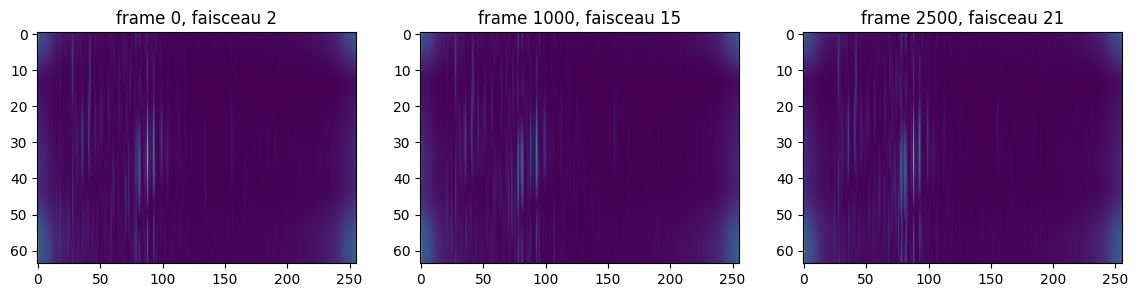

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, i in zip(ax, [0, 1000, 2500]):
    a.imshow(maps[i, 0].astype("float32"), aspect="auto")
    a.set_title(f"frame {i}, faisceau {df.beam_label[i]}")
plt.show()
!mkdir -p /content/drive/MyDrive/beam_data_B
!cp /content/radar_maps.npy /content/drive/MyDrive/beam_data_B/

In [5]:
%cd /content/repo
!git pull
import importlib, src.radar; importlib.reload(src.radar)

/content/repo
Already up to date.


<module 'src.radar' from '/content/repo/src/radar.py'>

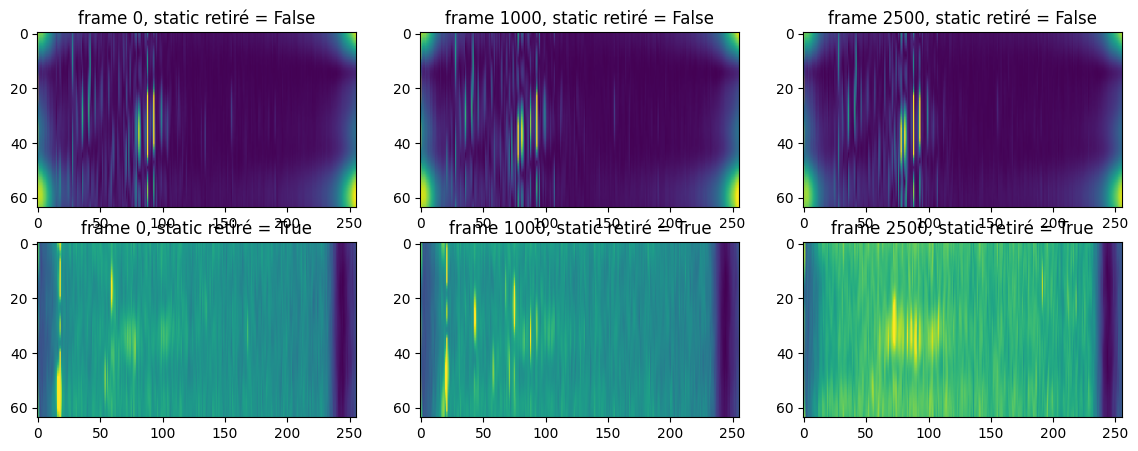

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
sys.path.insert(0, "/content/repo")
from src.radar import radar_to_range_angle, full_path
df = pd.read_csv("splits.csv")

fig, ax = plt.subplots(2, 3, figsize=(14, 5))
for j, i in enumerate([0, 1000, 2500]):
    cube = np.load(full_path("/content/data", df.unit1_radar[i]))
    for r, rs in enumerate([False, True]):
        ax[r, j].imshow(radar_to_range_angle(cube, remove_static=rs), aspect="auto")
        ax[r, j].set_title(f"frame {i}, static retiré = {rs}")
plt.show()

In [7]:
from src.radar import build_radar_cache
maps = build_radar_cache(df, "/content/data", "/content/radar_maps.npy")
print(maps.shape, maps.dtype)
!cp /content/radar_maps.npy /content/drive/MyDrive/beam_data_B/radar_maps.npy

100%|██████████| 3235/3235 [05:42<00:00,  9.45it/s]


(3235, 1, 64, 256) float16


In [8]:
import torch
from src.radar_models import RadarCNN
from src.train_radar import fit, predict
from src.evaluate import topk_accuracy

dev = "cuda"
X = torch.from_numpy(maps)
y = torch.tensor(df.beam_label.values)
tr, va, te = [torch.tensor((df.split == s).values) for s in ("train", "val", "test")]
sub = lambda m: (X[m], y[m])

radar = fit(RadarCNN(), sub(tr), sub(va), epochs=30, device=dev)
radar_logits = predict(radar, sub(te), dev)
print("TEST radar seul :", topk_accuracy(radar_logits, y[te]))
torch.save(radar.state_dict(), "/content/drive/MyDrive/beam_data_B/radar.pt")

epoch 01  loss 3.919  val top1 0.159  top3 0.273
epoch 02  loss 3.491  val top1 0.137  top3 0.231
epoch 03  loss 3.446  val top1 0.159  top3 0.273
epoch 04  loss 3.905  val top1 0.153  top3 0.249
epoch 05  loss 3.345  val top1 0.139  top3 0.235
epoch 06  loss 3.252  val top1 0.149  top3 0.233
epoch 07  loss 3.671  val top1 0.159  top3 0.243
epoch 08  loss 3.697  val top1 0.131  top3 0.265
epoch 09  loss 3.460  val top1 0.137  top3 0.259
epoch 10  loss 3.295  val top1 0.149  top3 0.282
epoch 11  loss 3.318  val top1 0.124  top3 0.267
epoch 12  loss 3.216  val top1 0.157  top3 0.253
epoch 13  loss 3.078  val top1 0.159  top3 0.276
epoch 14  loss 3.509  val top1 0.161  top3 0.269
epoch 15  loss 3.001  val top1 0.114  top3 0.235
epoch 16  loss 2.956  val top1 0.139  top3 0.241
epoch 17  loss 3.051  val top1 0.127  top3 0.241
epoch 18  loss 3.335  val top1 0.076  top3 0.173
epoch 19  loss 3.020  val top1 0.141  top3 0.245
epoch 20  loss 3.358  val top1 0.159  top3 0.288
epoch 21  loss 2.775

In [9]:
%cd /content/repo
!git pull

/content/repo
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 992 bytes | 496.00 KiB/s, done.
From https://github.com/nerminecheriaa/beam-prediction-deepsense6g
   9db5b08..a2e75a7  radar-fusion -> origin/radar-fusion
Updating 9db5b08..a2e75a7
Fast-forward
 src/radar.py        | 37 ++++++++++++++++++++++++-------------
 src/radar_models.py |  2 +-
 2 files changed, 25 insertions(+), 14 deletions(-)


In [10]:
from scipy.stats import spearmanr
Xf = maps[:, 0].astype("float32")
peak_ang = Xf.sum(axis=2).argmax(axis=1)      # angle dominant de chaque frame
for s in ("train", "val", "test"):
    m = (df.split == s).values
    print(s, spearmanr(peak_ang[m], df.beam_label[m]))

train SignificanceResult(statistic=np.float64(-0.06914813868175652), pvalue=np.float64(0.0009911575953313217))
val SignificanceResult(statistic=np.float64(-0.14323612787464038), pvalue=np.float64(0.0014779643063873376))
test SignificanceResult(statistic=np.float64(0.35325086359972524), pvalue=np.float64(1.4896089995772129e-15))


In [11]:
import importlib, src.radar; importlib.reload(src.radar)
from src.radar import build_radar_cache
maps2 = build_radar_cache(df, "/content/data", "/content/radar_maps_dop.npy", method="doppler")
!cp /content/radar_maps_dop.npy /content/drive/MyDrive/beam_data_B/

100%|██████████| 3235/3235 [07:03<00:00,  7.63it/s]


In [12]:
X = torch.from_numpy(maps2)
sub = lambda m: (X[m], y[m])
radar = fit(RadarCNN(), sub(tr), sub(va), epochs=20, lr=5e-4, device=dev)
radar_logits = predict(radar, sub(te), dev)
print("TEST radar seul :", topk_accuracy(radar_logits, y[te]))

epoch 01  loss 3.597  val top1 0.159  top3 0.271
epoch 02  loss 3.793  val top1 0.153  top3 0.263
epoch 03  loss 3.469  val top1 0.167  top3 0.269
epoch 04  loss 3.527  val top1 0.149  top3 0.257
epoch 05  loss 3.525  val top1 0.135  top3 0.276
epoch 06  loss 3.231  val top1 0.151  top3 0.276
epoch 07  loss 3.380  val top1 0.145  top3 0.271
epoch 08  loss 3.529  val top1 0.141  top3 0.257
epoch 09  loss 3.701  val top1 0.149  top3 0.271
epoch 10  loss 3.449  val top1 0.145  top3 0.241
epoch 11  loss 3.307  val top1 0.149  top3 0.280
epoch 12  loss 3.343  val top1 0.116  top3 0.255
epoch 13  loss 3.415  val top1 0.153  top3 0.267
epoch 14  loss 3.164  val top1 0.143  top3 0.269
epoch 15  loss 3.172  val top1 0.127  top3 0.235
epoch 16  loss 3.261  val top1 0.049  top3 0.167
epoch 17  loss 2.802  val top1 0.092  top3 0.202
epoch 18  loss 2.882  val top1 0.090  top3 0.194
epoch 19  loss 2.700  val top1 0.118  top3 0.208
epoch 20  loss 3.054  val top1 0.165  top3 0.280
TEST radar seul : {'

anciennes train -0.06
anciennes val 0.17
anciennes test 0.16
doppler train -0.02
doppler val 0.14
doppler test 0.06


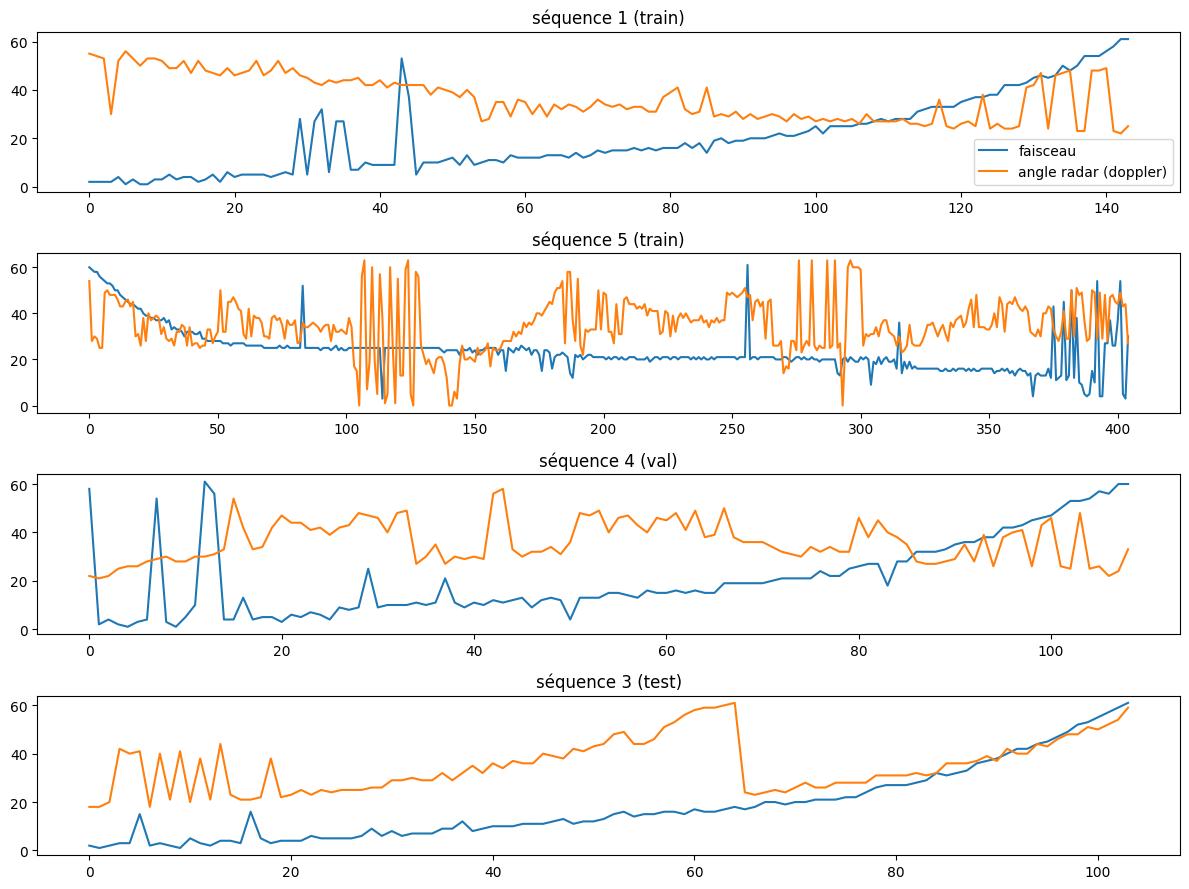

In [13]:
from scipy.ndimage import uniform_filter
from scipy.stats import spearmanr

def peak_angle(M):
    out = []
    for m in M[:, 0].astype("float32"):
        s = uniform_filter(m, size=5)
        out.append(np.unravel_index(s.argmax(), s.shape))
    return np.array(out)                 # colonnes : (angle, distance)

pk1, pk2 = peak_angle(maps), peak_angle(maps2)
for nom, pk in (("anciennes", pk1), ("doppler", pk2)):
    for s in ("train", "val", "test"):
        m = (df.split == s).values
        print(nom, s, round(spearmanr(pk[m, 0], df.beam_label[m])[0], 2))

fig, ax = plt.subplots(4, 1, figsize=(12, 9))
for a, sq in zip(ax, [1, 5, 4, 3]):
    m = (df.seq_index == sq).values
    a.plot(df.beam_label[m].values, label="faisceau")
    a.plot(pk2[m, 0], label="angle radar (doppler)")
    a.set_title(f"séquence {sq} ({df.split[m].iloc[0]})")
ax[0].legend(); plt.tight_layout(); plt.show()

In [14]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
!ls -lh /content/drive/MyDrive/beam_data/camera

Mounted at /content/drive
total 515M
-rw------- 1 root root 465M Nov  7 00:54 cam_cache_224.pt
-rw------- 1 root root 120K Nov  7 01:25 camera_errors_test.png
-rw------- 1 root root 7.2M Nov  7 01:25 camera_outputs.pt
-rw------- 1 root root 5.7K Nov  7 01:16 camera_resnet18_best_history.json
-rw------- 1 root root  43M Nov  7 01:15 camera_resnet18_best.pth
-rw------- 1 root root  10K Nov  7 01:25 camera_test_predictions.csv
-rw------- 1 root root 131K Nov  7 01:18 camera_training_curves.png


In [15]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q -n /content/drive/MyDrive/beam_data/scenario32.zip -d /content/data
!rm -rf /content/repo
!git clone -q -b radar-fusion https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo
%cd /content/repo

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: Unable to read current working directory: No such file or directory
[Errno 2] No such file or directory: '/content/repo'
/content/repo


In [16]:
%cd /content
!rm -rf /content/repo
!git clone -q -b radar-fusion https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo
%cd /content/repo
!ls src

/content
/content/repo
dataset.py   __init__.py  overhead.py	   radar.py  train_radar.py
evaluate.py  models.py	  radar_models.py  train.py


In [17]:
import sys; sys.path.insert(0, "/content/repo")
import torch, numpy as np, pandas as pd
from src.evaluate import topk_accuracy
dev = "cuda"

df = pd.read_csv("splits.csv")
X = torch.from_numpy(np.load("/content/drive/MyDrive/beam_data_B/radar_maps_dop.npy"))
y = torch.tensor(df.beam_label.values)
tr, va, te = [torch.tensor((df.split == s).values) for s in ("train", "val", "test")]
sub = lambda m: (X[m], y[m])

co = torch.load("/content/drive/MyDrive/beam_data/camera/camera_outputs.pt", weights_only=False)
for s in ("train", "val", "test"):
    m = (df.split == s).values
    assert (df["index"].values[m] == co[s]["index"].numpy()).all(), s
print("ordre OK | caméra test :", topk_accuracy(co["test"]["logits"], co["test"]["labels"]))

ordre OK | caméra test : {'top1': 0.16458334028720856, 'top3': 0.32083332538604736, 'top5': 0.48750001192092896}


In [18]:
from src.radar_models import RadarCNN, FusionNet, late_fusion
from src.train_radar import fit, predict
radar = fit(RadarCNN(), sub(tr), sub(va), epochs=20, lr=5e-4, device=dev)
rv, rt = predict(radar, sub(va), dev), predict(radar, sub(te), dev)
torch.save(radar.state_dict(), "/content/drive/MyDrive/beam_data_B/radar_dop.pt")
print("Radar test :", topk_accuracy(rt, y[te]))

epoch 01  loss 3.300  val top1 0.153  top3 0.265
epoch 02  loss 3.243  val top1 0.153  top3 0.253
epoch 03  loss 3.678  val top1 0.143  top3 0.267
epoch 04  loss 3.154  val top1 0.157  top3 0.255
epoch 05  loss 3.291  val top1 0.159  top3 0.269
epoch 06  loss 3.676  val top1 0.153  top3 0.271
epoch 07  loss 3.445  val top1 0.153  top3 0.265
epoch 08  loss 3.333  val top1 0.149  top3 0.269
epoch 09  loss 3.582  val top1 0.147  top3 0.273
epoch 10  loss 3.398  val top1 0.155  top3 0.267
epoch 11  loss 3.454  val top1 0.141  top3 0.280
epoch 12  loss 3.347  val top1 0.159  top3 0.271
epoch 13  loss 2.972  val top1 0.153  top3 0.278
epoch 14  loss 3.429  val top1 0.133  top3 0.269
epoch 15  loss 3.266  val top1 0.139  top3 0.261
epoch 16  loss 3.028  val top1 0.147  top3 0.265
epoch 17  loss 3.127  val top1 0.157  top3 0.271
epoch 18  loss 3.139  val top1 0.155  top3 0.278
epoch 19  loss 3.606  val top1 0.153  top3 0.271
epoch 20  loss 3.253  val top1 0.157  top3 0.267
Radar test : {'top1'

In [19]:
cv, ct = co["val"]["logits"], co["test"]["logits"]
score = lambda w: sum(topk_accuracy(late_fusion(cv, rv, w), y[va]).values())
w = max(np.arange(0, 1.01, 0.1), key=score)       # poids choisi sur la validation
late = late_fusion(ct, rt, w)
print("w_cam =", round(float(w), 1), topk_accuracy(late, y[te]))

w_cam = 0.9 {'top1': 0.16041666269302368, 'top3': 0.34583333134651184, 'top5': 0.512499988079071}


In [20]:
from src.dataset import build_image_cache, get_split
from src.models import CameraResNet18
from src.train import predict as cam_predict
cache = build_image_cache("/content/repo/splits.csv", "/content/data",
                          "/content/drive/MyDrive/beam_data/camera/cam_cache_224.pt")
base = CameraResNet18(pretrained=True).to(dev)       # ResNet18 NON affiné
feats = {s: cam_predict(base, get_split(cache, s)[0], dev, return_features=True)[1]
         for s in ("train", "val", "test")}

fusion = fit(FusionNet(RadarCNN()),
             (feats["train"], X[tr], y[tr]), (feats["val"], X[va], y[va]),
             epochs=20, lr=5e-4, device=dev)
ft = predict(fusion, (feats["test"], X[te], y[te]), dev)
print("Fusion concat :", topk_accuracy(ft, y[te]))

Cache rechargé depuis /content/drive/MyDrive/beam_data/camera/cam_cache_224.pt : (3235, 3, 224, 224)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


epoch 01  loss 3.652  val top1 0.159  top3 0.286
epoch 02  loss 3.556  val top1 0.157  top3 0.282
epoch 03  loss 3.129  val top1 0.157  top3 0.278
epoch 04  loss 3.023  val top1 0.161  top3 0.265
epoch 05  loss 3.268  val top1 0.114  top3 0.231
epoch 06  loss 3.080  val top1 0.133  top3 0.263
epoch 07  loss 3.094  val top1 0.118  top3 0.257
epoch 08  loss 2.710  val top1 0.143  top3 0.259
epoch 09  loss 3.597  val top1 0.104  top3 0.227
epoch 10  loss 3.071  val top1 0.051  top3 0.198
epoch 11  loss 2.830  val top1 0.110  top3 0.255
epoch 12  loss 2.484  val top1 0.110  top3 0.247
epoch 13  loss 2.943  val top1 0.094  top3 0.243
epoch 14  loss 2.887  val top1 0.047  top3 0.141
epoch 15  loss 2.854  val top1 0.069  top3 0.184
epoch 16  loss 2.953  val top1 0.045  top3 0.127
epoch 17  loss 2.446  val top1 0.080  top3 0.196
epoch 18  loss 2.553  val top1 0.041  top3 0.139
epoch 19  loss 2.837  val top1 0.047  top3 0.145
epoch 20  loss 3.025  val top1 0.039  top3 0.194
Fusion concat : {'to

In [21]:
from src.overhead import comparison_table
counts = torch.bincount(y[tr], minlength=64).float()
tab = comparison_table({
    "Fréquence (baseline)": counts.expand(int(te.sum()), 64),
    "Caméra seule": ct, "Radar seul": rt,
    "Fusion concat": ft, "Fusion tardive": late}, y[te])
print(tab.to_string())
tab.to_csv("/content/drive/MyDrive/beam_data_B/resultats_B.csv", index=False)

                Méthode  Top-1  Top-3  Top-5 Faisceaux testés              Gain
0    Balayage exhaustif  100.0  100.0  100.0               64               0 %
1  Fréquence (baseline)   13.1   36.3   42.3            1/3/5  98.4/95.3/92.2 %
2          Caméra seule   16.5   32.1   48.8            1/3/5  98.4/95.3/92.2 %
3            Radar seul   15.8   34.6   43.3            1/3/5  98.4/95.3/92.2 %
4         Fusion concat   20.4   33.3   41.0            1/3/5  98.4/95.3/92.2 %
5        Fusion tardive   16.0   34.6   51.2            1/3/5  98.4/95.3/92.2 %


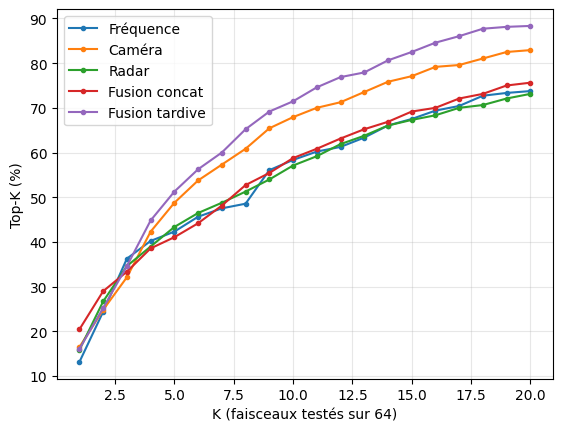

Fréquence        K pour atteindre 50 % : 9
Caméra           K pour atteindre 50 % : 6
Radar            K pour atteindre 50 % : 8
Fusion concat    K pour atteindre 50 % : 8
Fusion tardive   K pour atteindre 50 % : 5


In [22]:
import matplotlib.pyplot as plt
Ks = list(range(1, 21))
cands = {"Fréquence": counts.expand(int(te.sum()), 64), "Caméra": ct, "Radar": rt,
         "Fusion concat": ft, "Fusion tardive": late}
curves = {n: [100 * topk_accuracy(l, y[te], ks=(k,))[f"top{k}"] for k in Ks] for n, l in cands.items()}
for n, c in curves.items():
    plt.plot(Ks, c, label=n, marker="o", ms=3)
plt.xlabel("K (faisceaux testés sur 64)"); plt.ylabel("Top-K (%)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("/content/drive/MyDrive/beam_data_B/topk_curves.png", dpi=200, bbox_inches="tight"); plt.show()
for n, c in curves.items():
    k50 = next((k for k, a in zip(Ks, c) if a >= 50), ">20")
    print(f"{n:16s} K pour atteindre 50 % :", k50)

In [23]:
res = {"Radar": [], "Fusion concat": []}
for seed in range(5):
    torch.manual_seed(seed)
    r = fit(RadarCNN(), sub(tr), sub(va), epochs=20, lr=5e-4, device=dev)
    res["Radar"].append(list(topk_accuracy(predict(r, sub(te), dev), y[te]).values()))
    f = fit(FusionNet(RadarCNN()), (feats["train"], X[tr], y[tr]), (feats["val"], X[va], y[va]),
            epochs=20, lr=5e-4, device=dev)
    res["Fusion concat"].append(list(topk_accuracy(predict(f, (feats["test"], X[te], y[te]), dev), y[te]).values()))
for n, v in res.items():
    v = 100 * np.array(v)
    print(n, "| moyenne Top-1/3/5 :", v.mean(0).round(1), "| écart-type :", v.std(0).round(1))

epoch 01  loss 3.399  val top1 0.157  top3 0.267
epoch 02  loss 3.279  val top1 0.157  top3 0.267
epoch 03  loss 3.777  val top1 0.157  top3 0.259
epoch 04  loss 3.186  val top1 0.143  top3 0.269
epoch 05  loss 3.378  val top1 0.151  top3 0.263
epoch 06  loss 3.386  val top1 0.139  top3 0.267
epoch 07  loss 3.296  val top1 0.149  top3 0.263
epoch 08  loss 3.382  val top1 0.149  top3 0.280
epoch 09  loss 3.218  val top1 0.145  top3 0.263
epoch 10  loss 3.141  val top1 0.153  top3 0.269
epoch 11  loss 3.141  val top1 0.135  top3 0.273
epoch 12  loss 3.267  val top1 0.141  top3 0.267
epoch 13  loss 3.526  val top1 0.149  top3 0.271
epoch 14  loss 3.002  val top1 0.149  top3 0.251
epoch 15  loss 3.376  val top1 0.116  top3 0.198
epoch 16  loss 3.247  val top1 0.149  top3 0.282
epoch 17  loss 2.821  val top1 0.153  top3 0.280
epoch 18  loss 3.669  val top1 0.153  top3 0.255
epoch 19  loss 3.136  val top1 0.143  top3 0.257
epoch 20  loss 3.192  val top1 0.086  top3 0.198
epoch 01  loss 3.797

In [24]:
seq = df.seq_index.values[te.numpy()]
print("w_cam =", round(float(w), 1))
for sq in np.unique(seq):
    m = torch.tensor(seq == sq)
    print(f"séquence {sq} ({int(m.sum())} frames)")
    for n, l in {"Caméra": ct, "Radar": rt, "Fusion tardive": late}.items():
        print("  ", n, {k: round(100 * v, 1) for k, v in topk_accuracy(l[m], y[te][m]).items()})

w_cam = 0.9
séquence 3 (104 frames)
   Caméra {'top1': 21.2, 'top3': 35.6, 'top5': 43.3}
   Radar {'top1': 5.8, 'top3': 8.7, 'top5': 17.3}
   Fusion tardive {'top1': 20.2, 'top3': 35.6, 'top5': 44.2}
séquence 14 (376 frames)
   Caméra {'top1': 15.2, 'top3': 31.1, 'top5': 50.3}
   Radar {'top1': 18.6, 'top3': 41.8, 'top5': 50.5}
   Fusion tardive {'top1': 14.9, 'top3': 34.3, 'top5': 53.2}
